In [45]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [46]:
df = pd.read_csv('heart.csv')
df

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1


In [47]:
df.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

In [48]:
df.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='str')

In [49]:
df.shape

(918, 12)

In [50]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [51]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 97.6 KB


# EDA and Data Cleaning

In [52]:
df.duplicated().sum()

np.int64(0)

In [53]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


<Axes: xlabel='HeartDisease'>

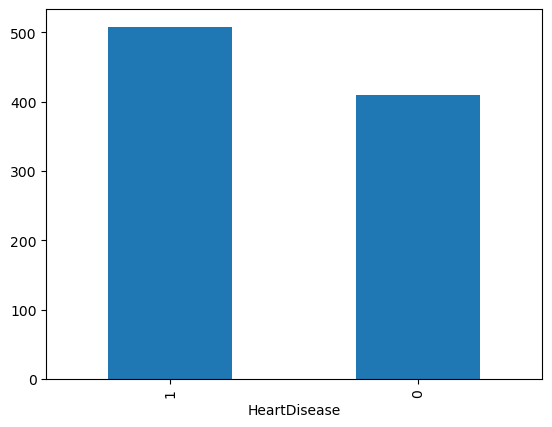

In [54]:
df['HeartDisease'].value_counts().plot(kind="bar")

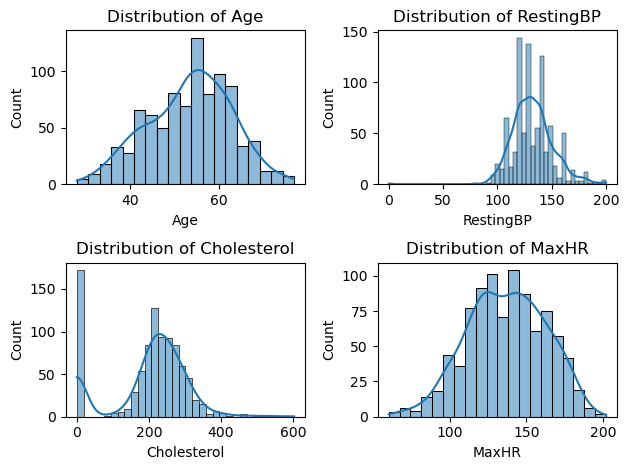

In [55]:
def plotting(var, num): 
    plt.subplot(2, 2, num)
    plt.title(f'Distribution of {var}')
    sns.histplot(df[var], kde=True)
plotting('Age', 1)
plotting('RestingBP', 2)
plotting('Cholesterol', 3) 
plotting('MaxHR', 4)

plt.tight_layout()

In [56]:
df['Cholesterol'].value_counts()

Cholesterol
0      172
254     11
223     10
220     10
211      9
      ... 
353      1
278      1
157      1
176      1
131      1
Name: count, Length: 222, dtype: int64

In [57]:
ch_mean = df.loc[df['Cholesterol'] != 0, 'Cholesterol'].mean()

In [58]:
df['Cholesterol'] = df['Cholesterol'].replace(0, ch_mean)
df['Cholesterol'] = df['Cholesterol'].round(2)

In [59]:
ch_mean = df.loc[df['RestingBP'] != 0, 'RestingBP'].mean()

df['RestingBP'] = df['RestingBP'].replace(0, ch_mean)
df['RestingBP'] = df['RestingBP'].round(2)

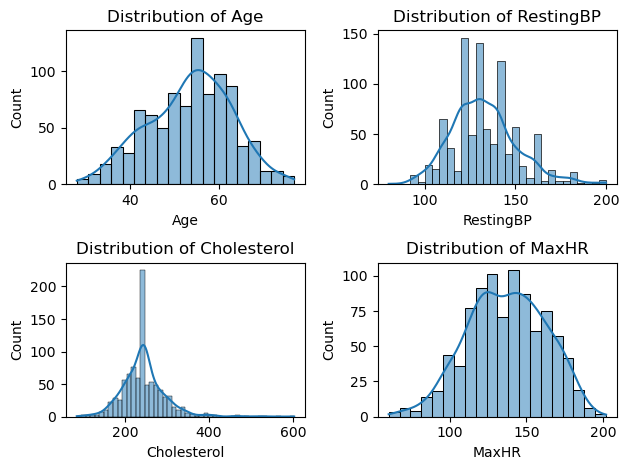

In [60]:
def plotting(var, num): 
    plt.subplot(2, 2, num)
    plt.title(f'Distribution of {var}')
    sns.histplot(df[var], kde=True)
plotting('Age', 1)
plotting('RestingBP', 2)
plotting('Cholesterol', 3) 
plotting('MaxHR', 4)

plt.tight_layout()

In [61]:
pip install sheryanalysis==0.1.0

Note: you may need to restart the kernel to use updated packages.


In [62]:
import sheryanalysis as sh 
sh.analyze(df)


🔍 Basic Analysis Report
------------------------------------------------------------
📏 Shape: (918, 12)
🧱 Columns: ['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']

✅ No null values found

🔠 Categorical Columns: ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope', 'HeartDisease']

🔢 Numerical Columns: ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']


{'shape': (918, 12),
 'columns': ['Age',
  'Sex',
  'ChestPainType',
  'RestingBP',
  'Cholesterol',
  'FastingBS',
  'RestingECG',
  'MaxHR',
  'ExerciseAngina',
  'Oldpeak',
  'ST_Slope',
  'HeartDisease'],
 'dtypes': {'Age': dtype('int64'),
  'Sex': <StringDtype(na_value=nan)>,
  'ChestPainType': <StringDtype(na_value=nan)>,
  'RestingBP': dtype('float64'),
  'Cholesterol': dtype('float64'),
  'FastingBS': dtype('int64'),
  'RestingECG': <StringDtype(na_value=nan)>,
  'MaxHR': dtype('int64'),
  'ExerciseAngina': <StringDtype(na_value=nan)>,
  'Oldpeak': dtype('float64'),
  'ST_Slope': <StringDtype(na_value=nan)>,
  'HeartDisease': dtype('int64')},
 'null_counts': {'Age': 0,
  'Sex': 0,
  'ChestPainType': 0,
  'RestingBP': 0,
  'Cholesterol': 0,
  'FastingBS': 0,
  'RestingECG': 0,
  'MaxHR': 0,
  'ExerciseAngina': 0,
  'Oldpeak': 0,
  'ST_Slope': 0,
  'HeartDisease': 0},
 'total_rows': 918,
 'column_types': {'categorical': ['Sex',
   'ChestPainType',
   'FastingBS',
   'RestingECG',

<Axes: xlabel='Sex', ylabel='count'>

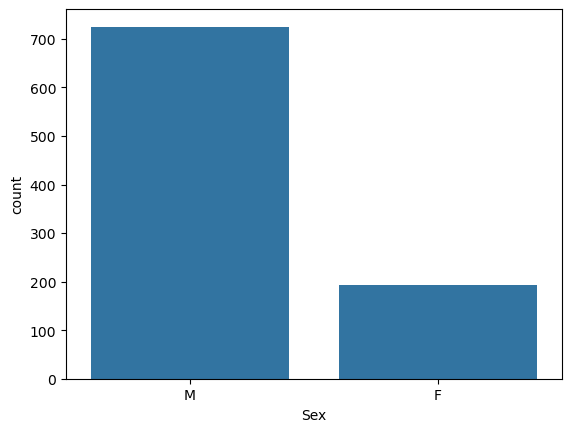

In [63]:
sns.countplot(x = df['Sex'])

<Axes: xlabel='Sex', ylabel='count'>

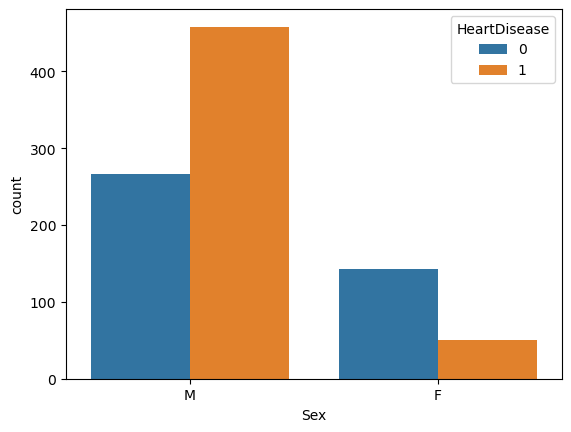

In [64]:
sns.countplot(x = df['Sex'], hue=df['HeartDisease'])

<Axes: xlabel='ChestPainType', ylabel='count'>

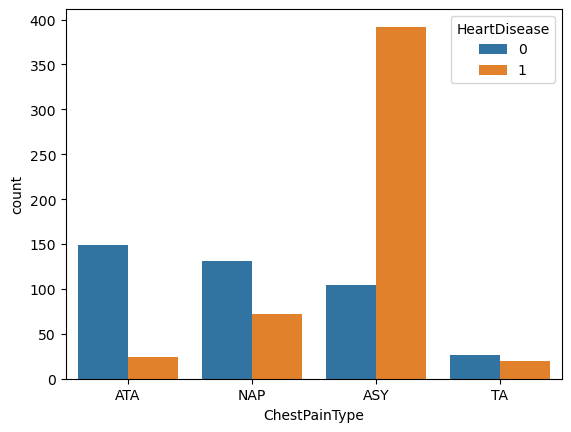

In [65]:
sns.countplot(x=df['ChestPainType'], hue=df['HeartDisease'])

<Axes: xlabel='FastingBS', ylabel='count'>

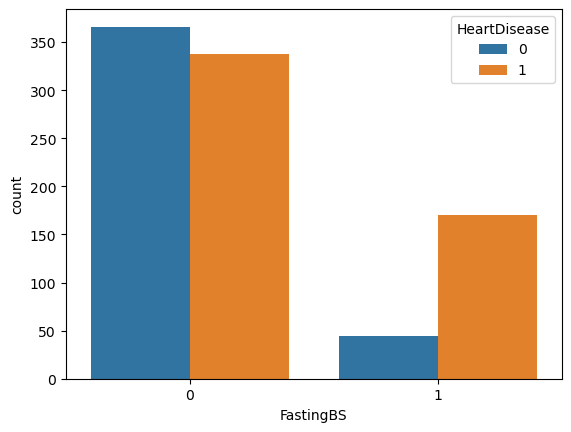

In [66]:
sns.countplot(x=df['FastingBS'], hue=df['HeartDisease'])

<Axes: xlabel='Cholesterol'>

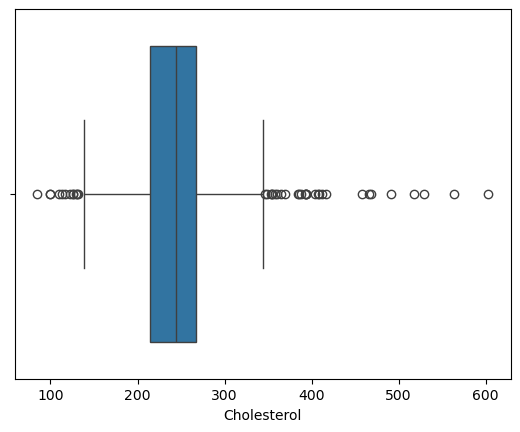

In [67]:
sns.boxplot(x='Cholesterol', data=df)

<Axes: xlabel='HeartDisease', ylabel='Cholesterol'>

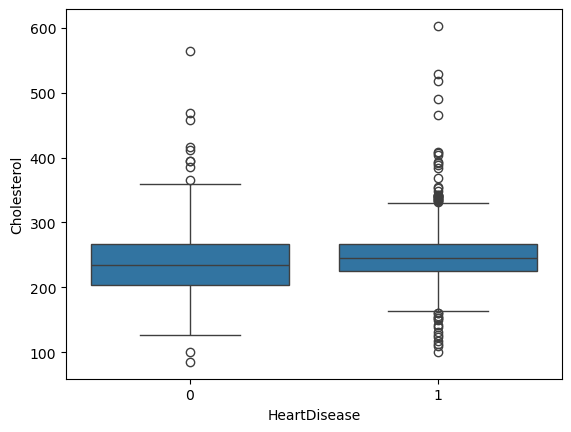

In [68]:
sns.boxplot(x='HeartDisease', y='Cholesterol', data=df)

<Axes: xlabel='HeartDisease', ylabel='Age'>

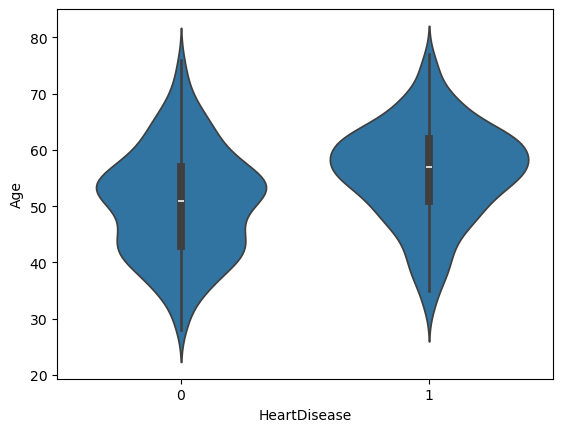

In [69]:
sns.violinplot(x='HeartDisease', y='Age', data=df)

<Axes: >

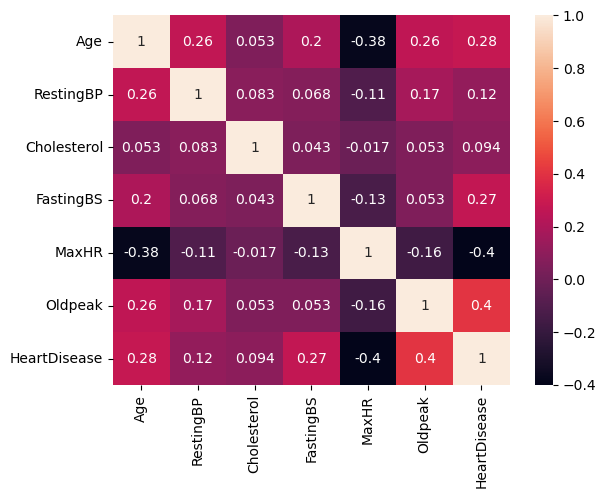

In [70]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

# Data Preprocessing and cleaning

In [71]:
df_encode = pd.get_dummies(df, drop_first=True)
df_encode = df_encode.astype(int)
df_encode

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0,0,1,1,0,0,1,0,0,0,1
1,49,160,180,0,156,1,1,0,0,1,0,1,0,0,1,0
2,37,130,283,0,98,0,0,1,1,0,0,0,1,0,0,1
3,48,138,214,0,108,1,1,0,0,0,0,1,0,1,1,0
4,54,150,195,0,122,0,0,1,0,1,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,110,264,0,132,1,1,1,0,0,1,1,0,0,1,0
914,68,144,193,1,141,3,1,1,0,0,0,1,0,0,1,0
915,57,130,131,0,115,1,1,1,0,0,0,1,0,1,1,0
916,57,130,236,0,174,0,1,0,1,0,0,0,0,0,1,0


# Standard Scaling

In [72]:
from sklearn.preprocessing import StandardScaler
numerical_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
scaler = StandardScaler()
df_encode[numerical_cols] = scaler.fit_transform(df_encode[numerical_cols])
df_encode.head()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,-1.433140,0.414885,0.834754,0,1.382928,-0.727592,0,1,1,0,0,1,0,0,0,1
1,-0.478484,1.527224,-1.210675,0,0.754157,0.282891,1,0,0,1,0,1,0,0,1,0
2,-1.751359,-0.141284,0.722161,0,-1.525138,-0.727592,0,1,1,0,0,0,1,0,0,1
3,-0.584556,0.303651,-0.572651,0,-1.132156,0.282891,1,0,0,0,0,1,0,1,1,0
4,0.051881,0.971054,-0.929194,0,-0.581981,-0.727592,0,1,0,1,0,1,0,0,0,1


In [73]:
from scipy.stats import pearsonr
import pandas as pd

# Features to check against target
selected_features = [
    col for col in df_encode.columns
    if col != 'HeartDisease'
]

# Calculate Pearson correlation
correlations = {
    feature: pearsonr(
        df_encode[feature],
        df_encode['HeartDisease']
    )[0]
    for feature in selected_features
}

# Create DataFrame
correlation_df = pd.DataFrame(
    list(correlations.items()),
    columns=['Feature', 'Pearson Correlation']
)

# Sort by absolute correlation
correlation_df['Abs Correlation'] = (
    correlation_df['Pearson Correlation'].abs()
)

correlation_df = correlation_df.sort_values(
    by='Abs Correlation',
    ascending=False
)

print(correlation_df)

              Feature  Pearson Correlation  Abs Correlation
14        ST_Slope_Up            -0.622164         0.622164
13      ST_Slope_Flat             0.554134         0.554134
12   ExerciseAngina_Y             0.494282         0.494282
7   ChestPainType_ATA            -0.401924         0.401924
4               MaxHR            -0.400421         0.400421
5             Oldpeak             0.392385         0.392385
6               Sex_M             0.305445         0.305445
0                 Age             0.282039         0.282039
3           FastingBS             0.267291         0.267291
8   ChestPainType_NAP            -0.212964         0.212964
1           RestingBP             0.117909         0.117909
11      RestingECG_ST             0.102527         0.102527
2         Cholesterol             0.092586         0.092586
10  RestingECG_Normal            -0.091580         0.091580
9    ChestPainType_TA            -0.054790         0.054790


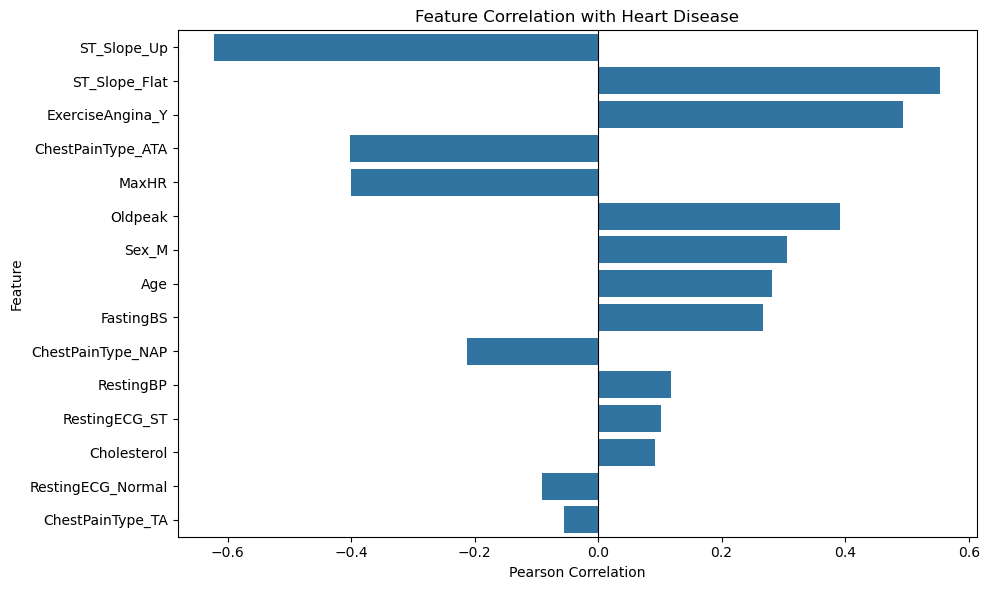

In [74]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=correlation_df,
    x='Pearson Correlation',
    y='Feature'
)

plt.title('Feature Correlation with Heart Disease')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

In [75]:

from scipy.stats import chi2_contingency
import pandas as pd

# ----------------------------------
# Chi-Square Test for Feature Selection
# ----------------------------------

alpha = 0.05

# Categorical features
cat_features = [
    'Sex',
    'ChestPainType',
    'FastingBS',
    'RestingECG',
    'ExerciseAngina',
    'ST_Slope'
]

# Dictionary to store results
chi2_results = {}

for col in cat_features:

    # Create contingency table
    contingency = pd.crosstab(
        df[col],
        df['HeartDisease']
    )

    # Perform Chi-Square test
    chi2_stat, p_val, dof, expected = chi2_contingency(
        contingency
    )

    # Make decision
    decision = (
        'Reject Null (Associated)'
        if p_val < alpha
        else 'Fail to Reject Null'
    )

    chi2_results[col] = {
        'chi2_statistic': chi2_stat,
        'p_value': p_val,
        'degrees_of_freedom': dof,
        'min_expected_frequency': expected.min(),
        'Decision': decision
    }

# Convert results into DataFrame
chi2_df = pd.DataFrame(chi2_results).T

# Sort by p-value
chi2_df = chi2_df.sort_values(
    by='p_value',
    ascending=True
)

# Display results
chi2_df


,chi2_statistic,p_value,degrees_of_freedom,min_expected_frequency,Decision
ST_Slope,355.918443,0.0,2,28.137255,Reject Null (Associated)
ChestPainType,268.067239,0.0,3,20.544662,Reject Null (Associated)
ExerciseAngina,222.259383,0.0,1,165.697168,Reject Null (Associated)
Sex,84.145101,0.0,1,86.198257,Reject Null (Associated)
FastingBS,64.320679,0.0,1,95.577342,Reject Null (Associated)
RestingECG,10.931469,0.004229,2,79.498911,Reject Null (Associated)


In [76]:
df_encode

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,-1.433140,0.414885,0.834754,0,1.382928,-0.727592,0,1,1,0,0,1,0,0,0,1
1,-0.478484,1.527224,-1.210675,0,0.754157,0.282891,1,0,0,1,0,1,0,0,1,0
2,-1.751359,-0.141284,0.722161,0,-1.525138,-0.727592,0,1,1,0,0,0,1,0,0,1
3,-0.584556,0.303651,-0.572651,0,-1.132156,0.282891,1,0,0,0,0,1,0,1,1,0
4,0.051881,0.971054,-0.929194,0,-0.581981,-0.727592,0,1,0,1,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,-0.902775,-1.253622,0.365619,0,-0.188999,0.282891,1,1,0,0,1,1,0,0,1,0
914,1.536902,0.637353,-0.966725,1,0.164684,2.303858,1,1,0,0,0,1,0,0,1,0
915,0.370100,-0.141284,-2.130180,0,-0.857069,0.282891,1,1,0,0,0,1,0,1,1,0
916,0.370100,-0.141284,-0.159813,0,1.461525,-0.727592,1,0,1,0,0,0,0,0,1,0


In [77]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

In [78]:
X = df_encode.drop('HeartDisease', axis=1)
y = df_encode['HeartDisease']

In [79]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [80]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [81]:
models = {
    "Logistic Regression": LogisticRegression(),
    "KNN": KNeighborsClassifier(), 
    "Naive Bayes": GaussianNB(), 
    "Decision Tree": DecisionTreeClassifier(), 
    "SVM": SVC()
}

In [87]:
result = []
for name, model in models.items(): 
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    result.append({
        "model":name,
        "Accuracy":round(acc, 4),
        "F1-Score": round(f1, 4)
    })

In [88]:
result

[{'model': 'Logistic Regression', 'Accuracy': 0.8696, 'F1-Score': 0.8846},
 {'model': 'KNN', 'Accuracy': 0.8641, 'F1-Score': 0.8815},
 {'model': 'Naive Bayes', 'Accuracy': 0.8478, 'F1-Score': 0.8614},
 {'model': 'Decision Tree', 'Accuracy': 0.8043, 'F1-Score': 0.82},
 {'model': 'SVM', 'Accuracy': 0.8478, 'F1-Score': 0.8667}]

In [90]:
import joblib
joblib.dump(models['Logistic Regression'], 'Logistic_Regression_heart.pkl')
joblib.dump(scaler, 'Scaler_heart.pkl')
joblib.dump(X.columns.tolist(), 'Columns_heart.pkl')

['Columns_heart.pkl']